# DATA37711 Homework 2 Question 3

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

In [4]:
# Experiment settings
TREE_COUNTS = [1, 10, 100, 300, 1000]
RANDOM_STATE = 42
TEST_SIZE = 0.30

# Function for one dataset
def evaluate_boosting(filename, dataset_name):
    # The CSV files have no header row.
    df = pd.read_csv(filename, header=None)

    # Predict the first column using all remaining columns.
    y = df.iloc[:, 0].astype(int)
    X = df.iloc[:, 1:]

    print(f"\n{'=' * 50}")
    print(dataset_name)
    print(f"{'=' * 50}")
    print("Dataset shape:", df.shape)
    print("Missing values:", df.isna().sum().sum())
    print("Class counts:")
    print(y.value_counts().sort_index())

    # Use the same split for all five models.
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=y
    )

    print("Training samples:", len(X_train))
    print("Test samples:", len(X_test))

    records = []

    for n_trees in TREE_COUNTS:
        # Only the number of trees changes between models.
        model = GradientBoostingClassifier(
            n_estimators=n_trees,
            learning_rate=0.1,
            max_depth=3,
            random_state=RANDOM_STATE
        )

        model.fit(X_train, y_train)

        train_pred = model.predict(X_train)
        test_pred = model.predict(X_test)

        train_error = 1 - accuracy_score(y_train, train_pred)
        test_error = 1 - accuracy_score(y_test, test_pred)

        records.append({
            "Dataset": dataset_name,
            "Trees": n_trees,
            "Train error": train_error,
            "Test error": test_error,
            "Generalization gap": test_error - train_error
        })

    results = pd.DataFrame(records)

    print("\nResults:")
    print(results.round(6).to_string(index=False))

    return results

## a) dset0

In [5]:

# Part a): dset0
results0 = evaluate_boosting("dset0.csv", "dset0")


dset0
Dataset shape: (500, 6)
Missing values: 0
Class counts:
0
0    287
1    213
Name: count, dtype: int64
Training samples: 350
Test samples: 150

Results:
Dataset  Trees  Train error  Test error  Generalization gap
  dset0      1     0.425714    0.426667            0.000952
  dset0     10     0.148571    0.253333            0.104762
  dset0    100     0.005714    0.153333            0.147619
  dset0    300     0.000000    0.166667            0.166667
  dset0   1000     0.000000    0.146667            0.146667


## b) dset1

In [6]:
results1 = evaluate_boosting("dset1.csv", "dset1")


dset1
Dataset shape: (500, 6)
Missing values: 0
Class counts:
0
0    273
1    227
Name: count, dtype: int64
Training samples: 350
Test samples: 150

Results:
Dataset  Trees  Train error  Test error  Generalization gap
  dset1      1     0.248571    0.320000            0.071429
  dset1     10     0.117143    0.220000            0.102857
  dset1    100     0.005714    0.206667            0.200952
  dset1    300     0.000000    0.200000            0.200000
  dset1   1000     0.000000    0.213333            0.213333


## c) Compare


Combined results:
Dataset  Trees  Train error  Test error  Generalization gap
  dset0      1     0.425714    0.426667            0.000952
  dset0     10     0.148571    0.253333            0.104762
  dset0    100     0.005714    0.153333            0.147619
  dset0    300     0.000000    0.166667            0.166667
  dset0   1000     0.000000    0.146667            0.146667
  dset1      1     0.248571    0.320000            0.071429
  dset1     10     0.117143    0.220000            0.102857
  dset1    100     0.005714    0.206667            0.200952
  dset1    300     0.000000    0.200000            0.200000
  dset1   1000     0.000000    0.213333            0.213333


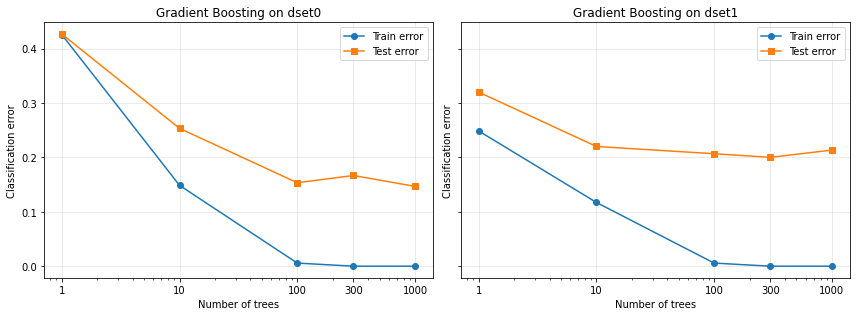


Saved: Q3_boosting_errors.png
Saved: Q3_boosting_results.csv


In [7]:
# Combined results
all_results = pd.concat(
    [results0, results1],
    ignore_index=True
)

print("\nCombined results:")
print(all_results.round(6).to_string(index=False))

# Plot train and test errors
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.5),
    sharey=True
)

for ax, results, name in zip(
    axes,
    [results0, results1],
    ["dset0", "dset1"]
):
    ax.plot(
        results["Trees"],
        results["Train error"],
        marker="o",
        label="Train error"
    )

    ax.plot(
        results["Trees"],
        results["Test error"],
        marker="s",
        label="Test error"
    )

    ax.set_xscale("log")
    ax.set_xticks(TREE_COUNTS)
    ax.set_xticklabels([str(n) for n in TREE_COUNTS])

    ax.set_xlabel("Number of trees")
    ax.set_ylabel("Classification error")
    ax.set_title(f"Gradient Boosting on {name}")
    ax.grid(alpha=0.3)
    ax.legend()

fig.tight_layout()

# Save a figure
fig.savefig(
    "Q3_boosting_errors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save numerical results
all_results.to_csv(
    "Q3_boosting_results.csv",
    index=False
)

print("\nSaved: Q3_boosting_errors.png")
print("Saved: Q3_boosting_results.csv")